In [1]:
import scanpy as sp
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pydeseq2 as deseq2

In [2]:
# import Anndata obj
adata_link = "data/Anndata/filtered/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3b_v2.h5ad"

adata = sp.read(adata_link)

In [3]:
adata

AnnData object with n_obs × n_vars = 2988 × 6248
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_counts', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'group'
    var: 'gene_id', 'final_gene_name', 'symbol_renamed', 'Gene Type', 'Name', 'Protein accession', 'symbol_old', 'locus_tag_old'
    uns: 'gene_metadata_added', 'gene_metadata_source', 'genes_with_metadata', 'matrix_type', 'name', 'source', 'total_genes'

In [4]:
# Check if we have raw counts matrix
print("Checking data matrices:")
print(f"Main matrix (X): {adata.X.shape}, type: {type(adata.X)}")
print(f"Has raw matrix: {'raw' in adata.layers if adata.layers else 'No layers'}")

if hasattr(adata, "raw") and adata.raw is not None:
    print(f"Raw matrix: {adata.raw.X.shape}")
    print("Using raw matrix for pseudobulk")
    count_matrix = adata.raw.X
elif "raw" in adata.layers:
    print("Using raw layer for pseudobulk")
    count_matrix = adata.layers["raw"]
else:
    print("Using main X matrix (assuming it contains raw counts)")
    count_matrix = adata.X

print(f"Selected matrix shape: {count_matrix.shape}")
print(f"Matrix type: {type(count_matrix)}")

# Check if counts look like raw counts (should be integers or close to integers)
if hasattr(count_matrix, "todense"):
    sample_values = count_matrix[:10, :10].todense()
else:
    sample_values = count_matrix[:10, :10]

print(f"Sample values from matrix:\n{sample_values}")

Checking data matrices:
Main matrix (X): (2988, 6248), type: <class 'scipy.sparse._csc.csc_matrix'>
Has raw matrix: No layers
Using main X matrix (assuming it contains raw counts)
Selected matrix shape: (2988, 6248)
Matrix type: <class 'scipy.sparse._csc.csc_matrix'>
Sample values from matrix:
[[56  0  0 93  0  0  0  0  0  0]
 [50  0  0 81  0  0  0  0  0  0]
 [41  0  0 88  0  0  0  1  0  0]
 [48  0  0 79  0  0  0  0  0  0]
 [46  0  0 78  0  0  0  0  0  0]
 [50  0  0 71  0  0  0  0  0  0]
 [50  0  0 73  0  0  0  0  0  0]
 [44  0  0 77  0  0  0  0  0  0]
 [45  0  0 70  0  0  1  0  0  0]
 [44  0  0 64  0  0  0  0  0  0]]


je vais réaliser une analyse différentielle d'expression génique à l'aide de DESeq2. (pseudobulk en mergeant par OD) correspond à CultureMedium_RepBio_OD donc 18 échantillons.

In [ ]:
# Create pseudobulk samples with pseudo-replicates by OD
import scanpy as sc
import random
import numpy as np

pbs = []
for od_value in adata.obs.OD.unique():
    od_subset = adata[adata.obs["OD"] == od_value]

    # Make sure to use raw data if available
    if hasattr(adata, "raw") and adata.raw is not None:
        od_subset.X = od_subset.raw.X
    elif "raw" in adata.layers:
        od_subset.X = od_subset.layers["raw"]
    # else use current X (assuming it's raw)

    # Create pseudo-replicates by randomly splitting cells
    indices = list(od_subset.obs_names)
    random.shuffle(indices)
    indices = np.array_split(np.array(indices), 2)  # 2 pseudo-replicates per OD

    for i, pseudo_rep in enumerate(indices):
        # Sum counts for this pseudo-replicate
        rep_subset = od_subset[indices[i]]
        summed_counts = rep_subset.X.sum(axis=0)

        # Convert to proper array format
        if hasattr(summed_counts, "A1"):
            summed_counts = summed_counts.A1
        elif hasattr(summed_counts, "toarray"):
            summed_counts = summed_counts.toarray().flatten()
        else:
            summed_counts = np.asarray(summed_counts).flatten()

        # Create pseudobulk AnnData object
        rep_adata = sc.AnnData(X=summed_counts.reshape(1, -1), var=rep_subset.var[[]])

        rep_adata.obs_names = [f"OD_{od_value}_rep_{i}"]
        rep_adata.obs["OD"] = od_value
        rep_adata.obs["replicate"] = i
        rep_adata.obs["CultureMedium"] = od_subset.obs["CultureMedium"].iloc[0]
        rep_adata.obs["RepBio"] = od_subset.obs["RepBio"].iloc[0]
        rep_adata.obs["n_cells"] = len(rep_subset)

        pbs.append(rep_adata)

print(f"Created {len(pbs)} pseudobulk samples with pseudo-replicates")
for pb in pbs:
    print(
        f"Sample: {pb.obs_names[0]}, OD: {pb.obs['OD'].iloc[0]}, replicate: {pb.obs['replicate'].iloc[0]}, n_cells: {pb.obs['n_cells'].iloc[0]}"
    )

In [ ]:
# Prepare data for DESeq2 analysis
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

# Concatenate pseudobulk samples
pb_combined = sc.concat(pbs, axis=0)

print(f"Combined pseudobulk data: {pb_combined.shape}")
print("Sample metadata:")
print(pb_combined.obs)

# Prepare count matrix and metadata for DESeq2
counts_df = pd.DataFrame(
    pb_combined.X, index=pb_combined.obs_names, columns=pb_combined.var_names
).astype(int)

metadata_df = pb_combined.obs.copy()
metadata_df["OD"] = metadata_df["OD"].astype(str)  # Convert to string for DESeq2

print(f"\nCount matrix shape: {counts_df.shape}")
print(f"Metadata shape: {metadata_df.shape}")
print(f"OD levels: {metadata_df['OD'].unique()}")

# Create DESeq2 dataset
dds = DeseqDataSet(counts=counts_df, metadata=metadata_df, design_factors=["OD"])

print(f"\nDESeq2 dataset created successfully!")
print(f"Samples: {dds.n_obs}, Genes: {dds.n_vars}")

Combined pseudobulk data: (18, 6248)
Sample metadata:
                     OD CultureMedium RepBio  n_cells
OD_M9F_A_OD1  M9F_A_OD1           M9F  M9F_A      166
OD_M9F_A_OD2  M9F_A_OD2           M9F  M9F_A      166
OD_M9F_A_OD3  M9F_A_OD3           M9F  M9F_A      166
OD_M9F_B_OD1  M9F_B_OD1           M9F  M9F_B      166
OD_M9F_B_OD2  M9F_B_OD2           M9F  M9F_B      166
OD_M9F_B_OD3  M9F_B_OD3           M9F  M9F_B      166
OD_M9F_C_OD1  M9F_C_OD1           M9F  M9F_C      166
OD_M9F_C_OD2  M9F_C_OD2           M9F  M9F_C      166
OD_M9F_C_OD3  M9F_C_OD3           M9F  M9F_C      166
OD_M9_A_OD1    M9_A_OD1            M9   M9_A      166
OD_M9_A_OD2    M9_A_OD2            M9   M9_A      166
OD_M9_A_OD3    M9_A_OD3            M9   M9_A      166
OD_M9_B_OD1    M9_B_OD1            M9   M9_B      166
OD_M9_B_OD2    M9_B_OD2            M9   M9_B      166
OD_M9_B_OD3    M9_B_OD3            M9   M9_B      166
OD_M9_C_OD1    M9_C_OD1            M9   M9_C      166
OD_M9_C_OD2    M9_C_OD2     

/tmp/ipykernel_17432/1353125858.py:27: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(


In [10]:
dds

AnnData object with n_obs × n_vars = 18 × 6248
    obs: 'OD', 'CultureMedium', 'RepBio', 'n_cells'
    obsm: 'design_matrix', 'size_factors'
    varm: '_normed_means', 'non_zero'
    layers: 'normed_counts'

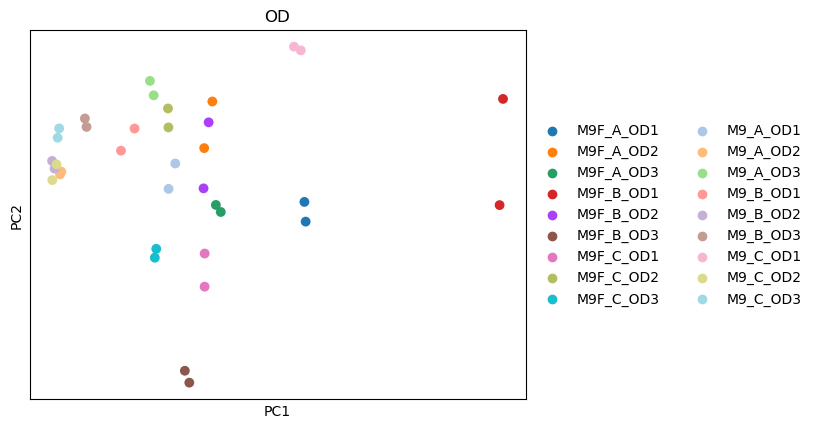

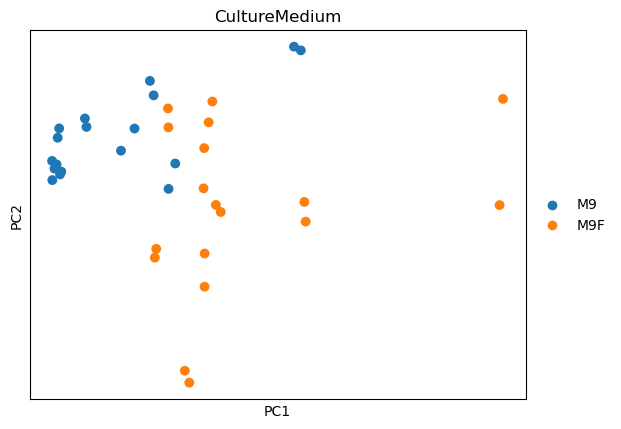

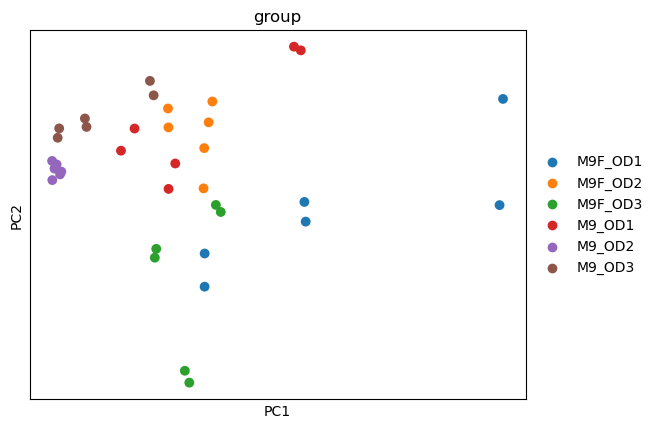

In [19]:
sc.tl.pca(dds)
sc.pl.pca(dds, color="OD", size=200)
sc.pl.pca(dds, color="CultureMedium", size=200)


# create new variable that exclude ce qui est entre _***_ de OD
dds.obs["group"] = dds.obs["OD"].str.replace(r"_.*_", "_", regex=True)

sc.pl.pca(dds, color="group", size=200)

In [ ]:
# Run DESeq2 differential expression analysis
print("Running DESeq2 analysis...")

# Fit the model (this may take a few minutes)
dds.deseq2()

print("DESeq2 fitting completed!")

# Get results for statistical testing - need to specify contrast
# Compare different OD levels (you can change this contrast)
stat_res = DeseqStats(
    dds, contrast=["OD", "M9F_A_OD1", "M9_A_OD1"]
)  # comparing sample M9F_A_OD1 vs M9_A_OD1

# Run statistical tests
stat_res.summary()

print("Statistical analysis completed!")
print(f"Results available for {len(stat_res.results_df)} genes")

Running DESeq2 analysis...
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.06 seconds.

Fitting dispersions...
... done in 0.76 seconds.

Fitting dispersion trend curve...
... done in 0.19 seconds.

Fitting MAP dispersions...
... done in 1.44 seconds.

Fitting LFCs...
... done in 1.67 seconds.

Calculating cook's distance...
... done in 0.05 seconds.

Replacing 0 outlier genes.

Running Wald tests...


DESeq2 fitting completed!
Log2 fold change & Wald test p-value: OD M9F_A_OD1 vs M9_A_OD1
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene_name                                                                
QLH64-00005  1231.840496        0.037144  0.037480  0.991043  0.321664   
QLH64-00010     0.022591       -2.259723  9.090633 -0.248577  0.803688   
QLH64-00015     0.025772        0.617532  9.090547  0.067931  0.945840   
QLH64-00020  1989.615259        0.039942  0.030902  1.292549  0.196167   
rrf_1           0.194720        1.618267  8.419341  0.192208  0.847579   
...                  ...             ...       ...       ...       ...   
QLH64-31225     2.174973        0.175944  0.646217  0.272267  0.785416   
recA_2          1.174600       -0.016759  0.927482 -0.018069  0.985584   
QLH64-31235     0.900988        1.618473  2.602106  0.621986  0.533951   
QLH64-31240     0.194893        0.158379  6.461208  0.024512  0.980444   
QLH64-31245     0.46282

... done in 0.81 seconds.



In [ ]:
# Check available OD levels first to set proper contrast
print("Available OD levels in the data:")
print(sorted(metadata_df["OD"].unique()))

# You can modify the contrast based on your available OD values
# Format: ["factor", "numerator_level", "denominator_level"]

In [ ]:
# Examine DESeq2 results
results_df = stat_res.results_df

print("DESeq2 Results Summary:")
print(f"Total genes tested: {len(results_df)}")
print(f"Genes with padj < 0.05: {(results_df['padj'] < 0.05).sum()}")
print(f"Genes with padj < 0.01: {(results_df['padj'] < 0.01).sum()}")

# Show top differentially expressed genes
print("\nTop 10 most significant genes:")
top_genes = results_df.sort_values("padj").head(10)
print(top_genes[["baseMean", "log2FoldChange", "pvalue", "padj"]])

DESeq2 Results Summary:
Total genes tested: 6248
Genes with padj < 0.05: 0
Genes with padj < 0.01: 0

Top 10 most significant genes:
                baseMean  log2FoldChange    pvalue      padj
gene_name                                                   
QLH64-00005  1231.840496        0.037144  0.321664  0.980128
QLH64-20870     1.270241        0.176636  0.889839  0.980128
QLH64-20865     0.449562        2.618461  0.298275  0.980128
QLH64-20860     0.163908        0.621200  0.945517  0.980128
QLH64-20855     0.143201       -0.823663  0.929311  0.980128
ychF            5.221915        0.329360  0.662529  0.980128
pth             1.198369        0.760938  0.524832  0.980128
QLH64-20840    48.636854        0.247018  0.165750  0.980128
QLH64-20835    10.703802       -0.376659  0.361078  0.980128
QLH64-20875     1.610129       -0.631304  0.409731  0.980128
